In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const

import sys
RE_path = './RE_Solver/' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

import RE as RE

import importlib
importlib.reload(RE)

<module 'RE' from 'c:\\Users\\grace\\OneDrive - Wellesley College\\Desktop\\UROP_Fall2025\\RE_Solver\\RE.py'>

Iht = 147 kA


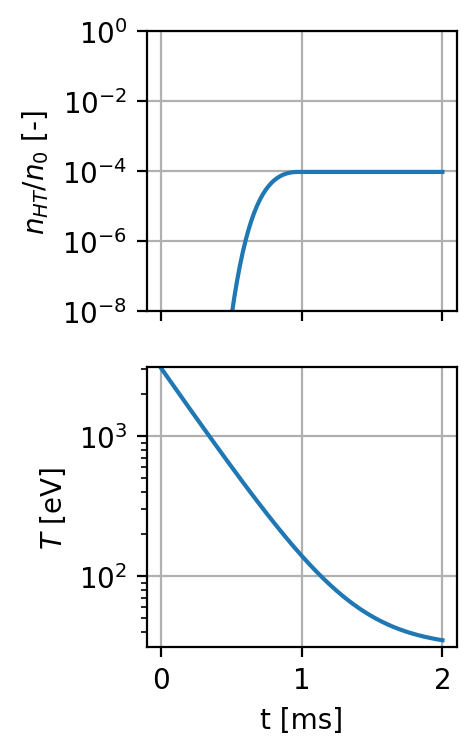

In [2]:
# Generate Fig. 5

def temperature(t, T0, Tf, t0):
    """
    Parameters:
    t: Time (s)
    T0: initial temp (eV)
    Tfinal: final temp (eV)
    t0: initial time (s)
    """
    return Tf + (T0 - Tf) * np.exp(-t / t0)


# Constants
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

t = np.linspace(0,2e-3,200)
nht = np.zeros_like(t)
nht_rate = np.zeros_like(t)

dt = np.diff(t)[0]

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    # Rate
    nht_rate[ii], nht[ii] = RE.get_HT_rate(ne=n0,
                                           T=T,
                                           t=t[ii],
                                           T0=T0,
                                           E0=E0,
                                           nht=nht[ii-1],
                                           dt=dt)

# Plot
fig, axs = plt.subplots(2,1,sharex=True,figsize=(2,4),dpi=200)
axs[0].plot(t*1e3,nht/n0,'-')
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8,1e0])
axs[0].grid()

axs[1].plot(t*1e3,temperature(t, T0, Tf, t0))
axs[1].set_yscale('log')
axs[1].set_ylabel('$T$ [eV]')
axs[1].set_ylim([Tf,T0])
axs[1].grid()
axs[-1].set_xlabel('t [ms]')
    
    
# HT Current
Iht = nht[-1] * const.c * const.e * np.pi * 0.6**2
print('Iht = %1.3g kA'%(Iht/1e3))

tt = 1*t
NHT = 1*nht

Text(0, 0.5, 'HT Rate [$m^{-3} ms^{-1}$]')

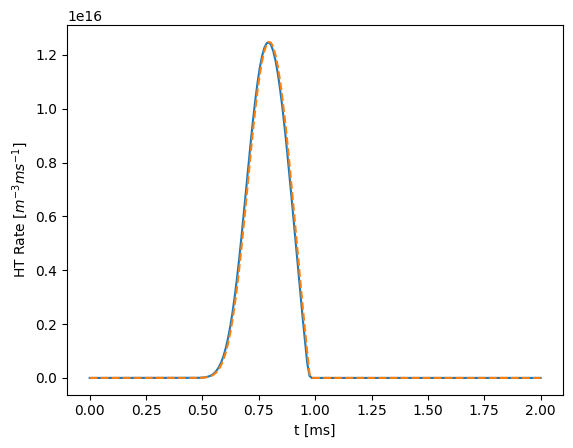

In [3]:
# The HT Rate

rate = np.gradient(nht,t)

plt.plot(t*1e3,rate / 1e3)
plt.plot(t*1e3,nht_rate / 1e3,'--')
plt.xlabel('t [ms]')
plt.ylabel('HT Rate [$m^{-3} ms^{-1}$]')




In [4]:
solver = RE.solver0D()
solver.display() 

Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


Hot tail on: 3484196.7308454
Hot tail off 3484196.7308454


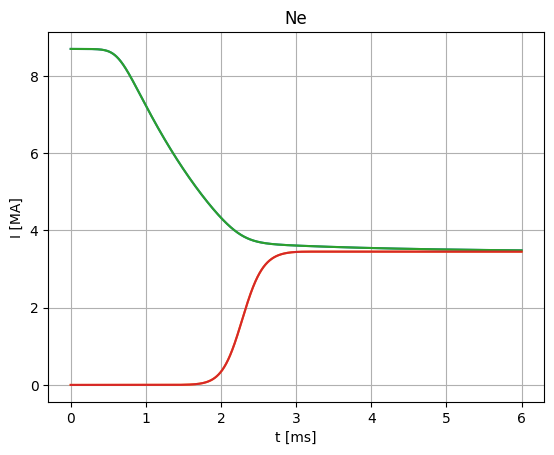

In [7]:
solver = RE.solver0D()


solver.k = 1.7
solver.Ir0 = 1e-1
solver.iDreicer = 1
solver.iHotTail = 1
solver.tmax = 6e-3

# Set impurity properties
solver.Z_imp = 10
solver.A_imp = 20
solver.n_imp = 1e21

# Solve
t, Ip, Ir, Wk = solver.solve()
print("Hot tail on:", Ip[-1])

plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.title('Ne')

solver = RE.solver0D()


solver.k = 1.7
solver.Ir0 = 1e-1
solver.iDreicer = 1
solver.iHotTail = 0
solver.tmax = 6e-3

# Set impurity properties
solver.Z_imp = 10
solver.A_imp = 20
solver.n_imp = 1e21

# Solve
t, Ip, Ir, Wk = solver.solve()
print("Hot tail off", Ip[-1])

plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
